# Étude des valeurs atypiques

Objectif : vérifier si des points atypiques dégradent **HistGB + `all_groups`**, et si leur traitement améliore réellement la MSE.
On conserve les cinq splits patients du benchmark, ses paramètres et son preprocessing.
Les lignes et cibles de validation ne sont jamais supprimées ni écrêtées ; les seuils sont appris sur le train seulement.
Les résidus de validation servent au diagnostic, jamais à sélectionner les lignes d'entraînement à retirer.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import GroupKFold, cross_val_predict

# Réutilise les définitions existantes, sans lancer leurs benchmarks ni la soumission.
benchmark = Path("features_engineering.ipynb")
if not benchmark.exists():
    benchmark = Path("exploration") / benchmark
source = json.loads(benchmark.read_text())["cells"]
for i in [1, 3, 5, 9, 11, 12]:
    exec("".join(source[i]["source"]))
model = models["HistGB"]
features = feature_experiments["all_groups"]

In [2]:
# Valeurs rares ≠ erreurs : contrôler d'abord les incohérences simples.
raw = X.join(y.rename("target"))
checks = {
    "Âge au diagnostic supérieur à l'âge de visite": (X.age_at_diagnosis > X.age).sum(),
    "Âge, dose ou délai négatif": (X[["age", "ledd", "time_since_intake_on", "time_since_intake_off"]] < 0).any(axis=1).sum(),
    "Doublons patient / âge": X.duplicated(["patient_id", "age"]).sum(),
    "OFF observé < ON observé (à inspecter, pas forcément erroné)": (X.off < X.on).sum(),
}
print(pd.Series(checks).to_string())
raw.select_dtypes("number").drop(columns="Index").describe(percentiles=[.01, .99]).T.round(2)

Âge au diagnostic supérieur à l'âge de visite                    0
Âge, dose ou délai négatif                                       0
Doublons patient / âge                                           0
OFF observé < ON observé (à inspecter, pas forcément erroné)    66


,count,mean,std,min,1%,99%,max
sexM,55603.0,0.60,0.49,0.0,0.00,1.0,1.0
age_at_diagnosis,52773.0,56.73,10.82,16.5,29.54,80.2,89.9
age,55603.0,62.52,11.48,16.5,34.40,87.9,103.3
ledd,35010.0,638.10,219.44,50.0,239.00,1280.0,1796.0
time_since_intake_on,29663.0,1.95,1.17,0.0,0.20,5.4,6.3
time_since_intake_off,11775.0,14.20,2.84,6.9,8.80,23.2,25.1
on,38944.0,21.99,10.37,0.0,3.00,51.0,95.0
off,32196.0,26.30,16.53,0.0,0.00,68.0,106.0
target,55603.0,37.33,16.50,0.0,1.80,73.1,109.5


## Référence et erreurs sur des patients non vus

Le preprocessing est ajusté une seule fois par split et mis en mémoire pour les essais suivants.
Comme `GroupShuffleSplit` répète des découpages 80/20, une visite peut être validée plusieurs fois.
Les diagnostics regroupent ces répétitions **par ligne**, en moyennant ses erreurs au carré.

In [3]:
exec("".join(source[7]["source"]))  # Les cinq folds imputés du benchmark.
folds, predictions = [], []
for i, fold in enumerate(clean_folds):
    prep = clone(feature_imputer)
    train = prep.fit_transform(fold["X_train"].join(features))
    val = prep.transform(fold["X_val"].join(features))
    fitted = clone(model).fit(train, fold["y_train"])
    pred = fitted.predict(val)
    folds.append(dict(train=train, val=val, y_train=fold["y_train"],
                      y_val=fold["y_val"], prediction=pred))
    predictions.append(pd.DataFrame({"fold": i, "row": val.index,
                                    "target": fold["y_val"].to_numpy(), "prediction": pred}))
oof = pd.concat(predictions, ignore_index=True)
oof["error"] = oof.prediction - oof.target
heldout = oof.groupby("row").agg(target=("target", "first"), prediction=("prediction", "mean"),
                                  MSE=("error", lambda s: np.mean(s**2)))
print(f"MSE de référence : {oof.groupby('fold').error.apply(lambda s: np.mean(s**2)).mean():.6f}")
print(f"Diagnostic : {len(heldout):,} visites de {X.loc[heldout.index, 'patient_id'].nunique():,} patients non vus.")

MSE de référence : 14.779276
Diagnostic : 37,214 visites de 4,667 patients non vus.


  File "/Users/Luc/Library/CloudStorage/OneDrive-Personal/Documents/Cours/MS2A/Apprentissage Statistique/Méthodologie/Challenge_Parkinson_disease/.venv/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/Luc/Library/CloudStorage/OneDrive-Personal/Documents/Cours/MS2A/Apprentissage Statistique/Méthodologie/Challenge_Parkinson_disease/.venv/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)
           ^^^^^^^^^^^^^


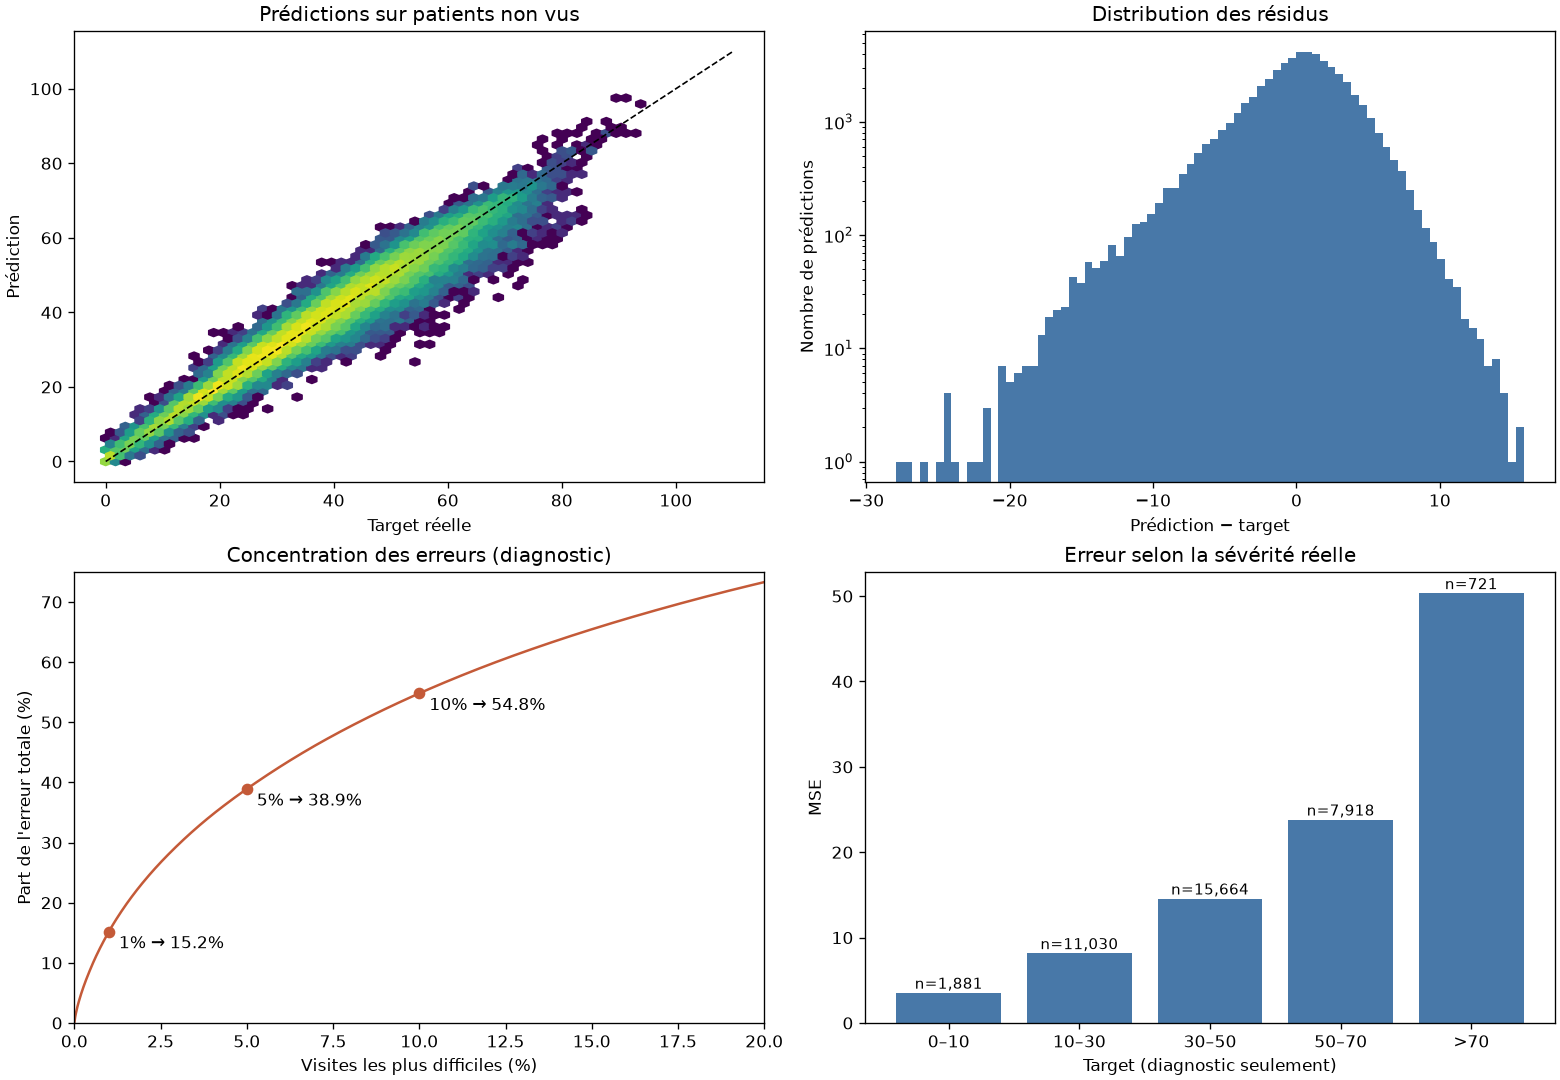

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
axes[0, 0].hexbin(heldout.target, heldout.prediction, gridsize=55, bins="log", mincnt=1, cmap="viridis")
axes[0, 0].plot([0, 110], [0, 110], "k--", lw=1)
axes[0, 0].set(title="Prédictions sur patients non vus", xlabel="Target réelle", ylabel="Prédiction")
axes[0, 1].hist(oof.error, bins=80, color="#4878a8")
axes[0, 1].set(title="Distribution des résidus", xlabel="Prédiction − target", ylabel="Nombre de prédictions", yscale="log")
ranked = heldout.MSE.sort_values(ascending=False).to_numpy()
x = np.arange(1, len(ranked) + 1) / len(ranked) * 100
cumulative = np.cumsum(ranked) / ranked.sum() * 100
axes[1, 0].plot(x, cumulative, color="#c45a38")
axes[1, 0].set(title="Concentration des erreurs (diagnostic)", xlabel="Visites les plus difficiles (%)", ylabel="Part de l'erreur totale (%)", xlim=(0, 20), ylim=(0, 75))
for pct in [1, 5, 10]:
    k = int(np.ceil(len(ranked) * pct / 100)) - 1
    axes[1, 0].plot(x[k], cumulative[k], "o", color="#c45a38")
    axes[1, 0].annotate(f"{pct}% → {cumulative[k]:.1f}%", (x[k], cumulative[k]), xytext=(6, -10), textcoords="offset points")
bands = heldout.groupby(pd.cut(heldout.target, [-1, 10, 30, 50, 70, 120]), observed=True).agg(MSE=("MSE", "mean"), n=("MSE", "size"))
axes[1, 1].bar(range(len(bands)), bands.MSE, color="#4878a8")
axes[1, 1].set_xticks(range(len(bands)), ["0–10", "10–30", "30–50", "50–70", ">70"])
axes[1, 1].set(title="Erreur selon la sévérité réelle", xlabel="Target (diagnostic seulement)", ylabel="MSE")
for j, row in enumerate(bands.itertuples()):
    axes[1, 1].text(j, row.MSE + .5, f"n={row.n:,}", ha="center", fontsize=9)
plt.show()

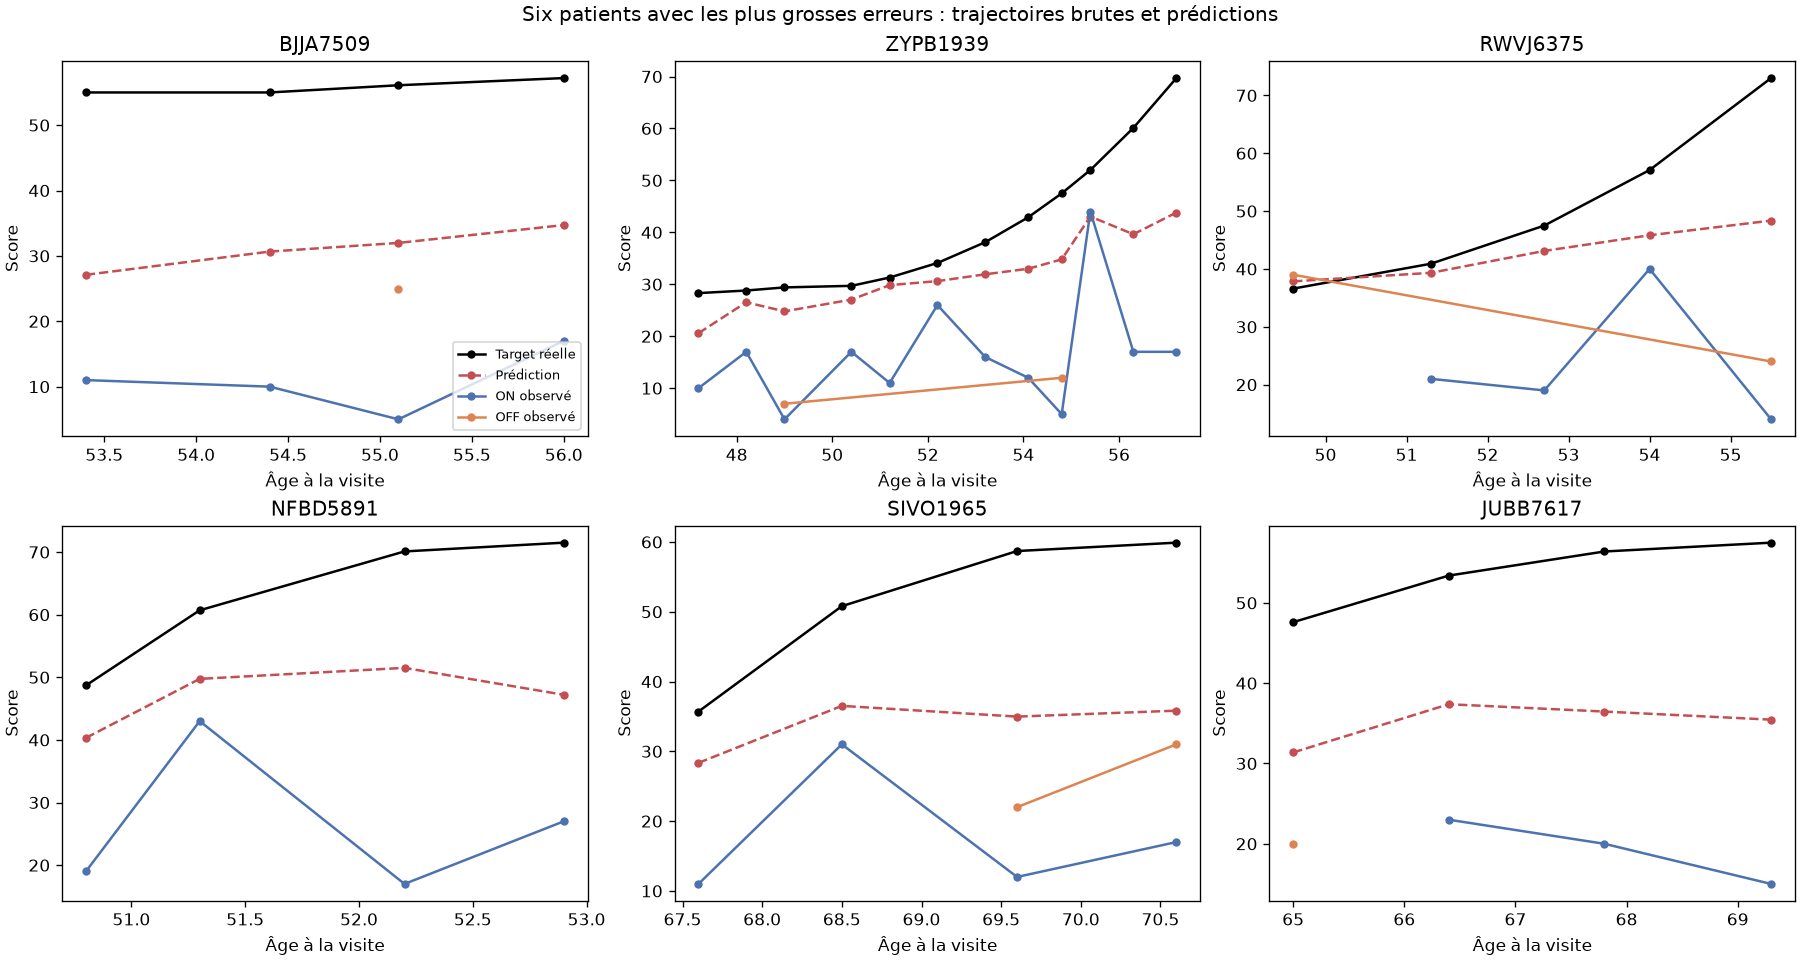

In [5]:
# Les trajectoires permettent de distinguer un pic isolé d'un patient mal prédit.
worst = X.loc[heldout.MSE.sort_values(ascending=False).index, "patient_id"].drop_duplicates().head(6)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
for ax, patient in zip(axes.flat, worst):
    visits = raw.loc[raw.patient_id.eq(patient)].sort_values("age").join(heldout[["prediction"]])
    for col, color, label in [("target", "black", "Target réelle"), ("prediction", "#c44e52", "Prédiction"),
                              ("on", "#4c72b0", "ON observé"), ("off", "#dd8452", "OFF observé")]:
        observed = visits.dropna(subset=[col])
        ax.plot(observed.age, observed[col], "o--" if col == "prediction" else "o-", color=color, label=label, ms=4)
    ax.set(title=patient, xlabel="Âge à la visite", ylabel="Score")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Six patients avec les plus grosses erreurs : trajectoires brutes et prédictions")
plt.show()

## Est-ce que retirer ces points améliore la validation ?

On teste des critères complémentaires : rareté des features (`IsolationForest`), extrêmes de la target,
et résidus élevés. Pour ces derniers, chaque exemple du train est prédit sans sa propre target,
avec **trois sous-folds patients** ; les features restent celles préparées sur le train extérieur.
On compare aussi une pondération de 0,25 pour le 1 % le plus difficile et une perte absolue.
Le score reste toujours la **MSE sur toutes les lignes de validation**.
Voir les documentations [IsolationForest / anomalies](https://scikit-learn.org/stable/modules/outlier_detection.html)
et [HistGB : pertes et poids](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html).

In [6]:
scores = []
for i, fold in enumerate(folds):
    train, val, yt, yv = fold["train"], fold["val"], fold["y_train"], fold["y_val"]
    inner = cross_val_predict(clone(model), train, yt, groups=X.loc[train.index, "patient_id"], cv=GroupKFold(3))
    residual = np.abs(yt.to_numpy() - inner)
    isolated = IsolationForest(contamination=.01, random_state=42, n_jobs=-1).fit_predict(train) == -1
    continuous = train.nunique() > 10  # Ne pas écrêter les indicatrices / catégories.
    low, high = train.quantile(.001).where(continuous), train.quantile(.999).where(continuous)
    target_limits = yt.quantile([.005, .995]).to_numpy()
    all_rows = np.ones(len(train), dtype=bool)
    cases = {
        "baseline": (train, val, all_rows, None, model),
        "clip_features_0.1%": (train.clip(low, high, axis=1), val.clip(low, high, axis=1), all_rows, None, model),
        "drop_target_tails_1%": (train, val, yt.between(*target_limits).to_numpy(), None, model),
        "drop_isolation_1%": (train, val, ~isolated, None, model),
        "downweight_residual_1%": (train, val, all_rows, np.where(residual > np.quantile(residual, .99), .25, 1.), model),
        "absolute_loss": (train, val, all_rows, None, clone(model).set_params(loss="absolute_error")),
    }
    for fraction in [.005, .01, .02]:
        cases[f"drop_residual_{100*fraction:g}%"] = (train, val, residual <= np.quantile(residual, 1-fraction), None, model)
    for name, (a, b, keep, weights, estimator) in cases.items():
        if name == "baseline":
            pred = fold["prediction"]
        else:
            fitted = clone(estimator).fit(a.loc[keep], yt.loc[keep], sample_weight=None if weights is None else weights[keep])
            pred = fitted.predict(b)
        scores.append(dict(strategy=name, fold=i, MSE=mean_squared_error(yv, pred)))
    print(f"Essais sur les exemples d'entraînement : split {i+1}/5 terminé.")

Essais sur les exemples d'entraînement : split 1/5 terminé.
Essais sur les exemples d'entraînement : split 2/5 terminé.
Essais sur les exemples d'entraînement : split 3/5 terminé.
Essais sur les exemples d'entraînement : split 4/5 terminé.
Essais sur les exemples d'entraînement : split 5/5 terminé.


## Vérification en amont des historiques

Un point extrême peut aussi perturber les médianes, pentes et mesures voisines du patient.
On teste donc un écrêtage des ON/OFF/LEDD bruts aux quantiles 0,1 % et 99,9 %,
puis un masquage des 0,5 % plus grands écarts à l'interpolation entre les mesures voisines.
Ces écarts utilisent uniquement les valeurs de **X**, sans target.
Les seuils sont appris sur le train et le preprocessing est réajusté pour chaque règle.

In [7]:
def spike_deviation(data):
    visits = data.sort_values(["patient_id", "age"])
    deviations = pd.DataFrame(index=data.index)
    for col in ["on", "off", "ledd"]:
        observed = visits[[col, "age"]].where(visits[col].notna(), axis=0)
        previous = observed.groupby(visits.patient_id).ffill().groupby(visits.patient_id).shift(1)
        future = observed.groupby(visits.patient_id).bfill().groupby(visits.patient_id).shift(-1)
        estimate = previous[col] + (future[col]-previous[col]) * (visits.age-previous.age) / (future.age-previous.age)
        deviations[col] = (visits[col] - estimate).abs()  # NaN aux bords, jamais masqués.
    return deviations

spikes = spike_deviation(X)
cols = ["on", "off", "ledd"]
for i, fold in enumerate(folds):
    raw_train, raw_val = X.loc[fold["train"].index], X.loc[fold["val"].index]
    low, high = raw_train[cols].quantile(.001), raw_train[cols].quantile(.999)
    cutoff = spikes.loc[raw_train.index].quantile(.995)
    for name in ["clip_raw_0.1%", "mask_patient_spikes_0.5%"]:
        train, val = raw_train.copy(), raw_val.copy()
        for part in [train, val]:
            part[cols] = (part[cols].clip(low, high, axis=1) if name.startswith("clip")
                          else part[cols].mask(spikes.loc[part.index].gt(cutoff)))
        prep = clone(preprocessing)
        a = prep.fit_transform(train).join(build_feature_groups(train)["all_groups"])
        b = prep.transform(val).join(build_feature_groups(val)["all_groups"])
        fitted = make_pipeline(clone(feature_imputer), clone(model)).fit(a, fold["y_train"])
        scores.append(dict(strategy=name, fold=i, MSE=mean_squared_error(fold["y_val"], fitted.predict(b))))
    print(f"Essais avant création des historiques : split {i+1}/5 terminé.")

Essais avant création des historiques : split 1/5 terminé.
Essais avant création des historiques : split 2/5 terminé.
Essais avant création des historiques : split 3/5 terminé.
Essais avant création des historiques : split 4/5 terminé.
Essais avant création des historiques : split 5/5 terminé.


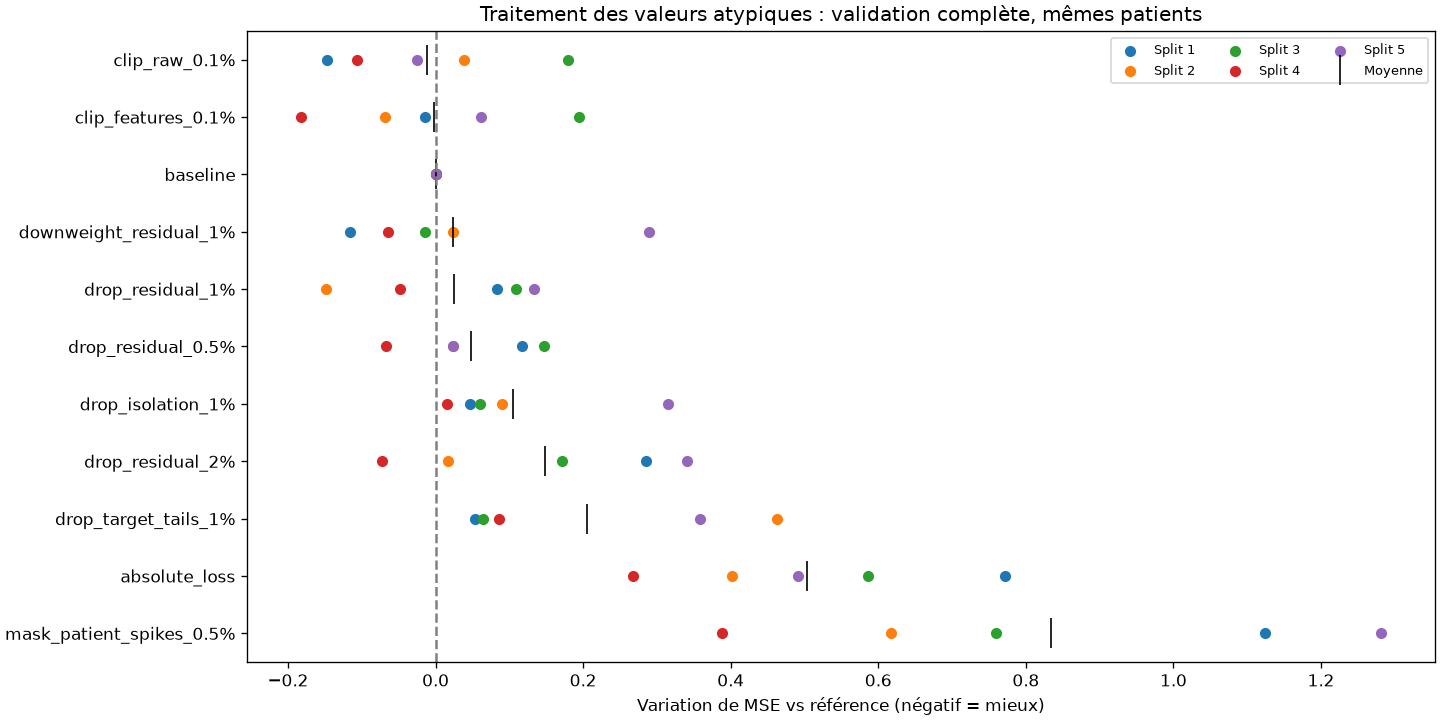

,MSE,std,gain_pct,splits_improved
strategy,,,,
clip_raw_0.1%,14.7670,0.2099,0.0830,3
clip_features_0.1%,14.7774,0.2839,0.0127,3
baseline,14.7793,0.3009,0.0000,0
downweight_residual_1%,14.8032,0.3573,-0.1622,3
drop_residual_1%,14.8049,0.3532,-0.1734,2
drop_residual_0.5%,14.8279,0.2905,-0.3292,1
drop_isolation_1%,14.8845,0.3549,-0.7121,0
drop_residual_2%,14.9274,0.3985,-1.0024,1
drop_target_tails_1%,14.9843,0.3323,-1.3875,0


In [8]:
scores = pd.DataFrame(scores)
summary = scores.groupby("strategy").agg(MSE=("MSE", "mean"), std=("MSE", lambda s: s.std(ddof=0)))
summary["gain_pct"] = 100 * (1 - summary.MSE / summary.loc["baseline", "MSE"])
paired = scores.pivot(index="strategy", columns="fold", values="MSE")
delta = paired - paired.loc["baseline"]
summary["splits_improved"] = delta.lt(0).sum(axis=1)
order = summary.sort_values("MSE").index
fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
for fold in delta.columns:
    ax.scatter(delta.loc[order, fold], np.arange(len(order)), label=f"Split {fold+1}", s=32)
ax.plot(delta.loc[order].mean(axis=1), np.arange(len(order)), "k|", markersize=18, label="Moyenne")
ax.axvline(0, color="grey", linestyle="--")
ax.set(yticks=np.arange(len(order)), yticklabels=order, xlabel="Variation de MSE vs référence (négatif = mieux)",
       title="Traitement des valeurs atypiques : validation complète, mêmes patients")
ax.invert_yaxis()
ax.legend(ncol=3, fontsize=8)
plt.show()
summary.loc[order].round(4)

## Conclusion

- La MSE de référence est **14,7793**. Parmi les 37 214 visites validées au moins une fois, les 1 % les plus difficiles représentent **15,2 %** de l'erreur totale. Ce constat ne prouve pas que leurs données sont erronées.
- Les plus grosses erreurs concernent souvent plusieurs visites cohérentes d'un même patient. La MSE augmente avec la target : **50,3** pour les targets >70, contre **14,6** entre 30 et 50. Le modèle sous-estime notamment certaines trajectoires élevées ; les supprimer ferait disparaître des cas utiles.
- Aucune suppression testée n'améliore la MSE moyenne. La perte absolue et le masquage des pics individuels la dégradent sur les **cinq splits**.
- Le meilleur score numérique vient de l'écrêtage des mesures brutes : **14,7670**, soit seulement **0,08 %** de gain, favorable sur **3 splits sur 5**. L'écrêtage après preprocessing donne **14,7774** : effet également minime et instable.

**Décision : conserver les données et la référence actuelle.** Les essais n'apportent pas de raison convaincante de supprimer des visites ou des patients. Cela ne garantit pas l'absence d'erreurs dans les données ; cela montre que les règles de nettoyage testées n'améliorent pas de façon convaincante ce modèle. Cette comparaison reste exploratoire, sur cinq découpages répétés qui partagent certains patients.